# **Data Science Tool Mastery Project**
### Project Title: **Customer Churn Analysis and Prediction Using Python and Machine Learning**


### Step 1: Importing Required Libraries

In [2]:
# Numerical Computing
import numpy as np

# Data Manipulation
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Display Settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")


All required libraries imported successfully!


### Step 2: Uploading and Loading the Dataset

In [5]:
import pandas as pd
from google.colab import files
from io import BytesIO

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 3: Dataset Exploration and Statistical Analysis

**Objective:** To explore the customer churn dataset using Pandas and NumPy, understand its structure, identify data types, and perform basic statistical analysis before preprocessing.

##### Step 3.1: Examine Dataset Information

In [6]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

##### Step 3.2: Descriptive Statistical Analysis

In [7]:
print("Numerical Statistics:")
display(df.describe())

print("\nCategorical Statistics:")
display(df.describe(include=['object', 'category']))

Numerical Statistics:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Categorical Statistics:


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


##### Step 3.3: Missing Values and Duplicate Analysis

In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Values in Each Column:")
print(df.nunique())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Records:
0

Unique Values in Each Column:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
Monthl

##### Step 3.4: Numerical Analysis Using NumPy

In [9]:
tenure = df['tenure'].to_numpy()

print("Average Customer Tenure:", np.mean(tenure))
print("Median Customer Tenure:", np.median(tenure))
print("Standard Deviation:", np.std(tenure))
print("Minimum Tenure:", np.min(tenure))
print("Maximum Tenure:", np.max(tenure))

Average Customer Tenure: 32.37114865824223
Median Customer Tenure: 29.0
Standard Deviation: 24.55773742286344
Minimum Tenure: 0
Maximum Tenure: 72


### Step 4: Data Cleaning and Preprocessing

**Objective:** To improve data quality by identifying and handling missing values, removing duplicate records, correcting data types, and preparing categorical features for machine learning.

Data preprocessing is an essential stage of the data science workflow because it ensures that the dataset is consistent, reliable, and suitable for further analysis.

##### Step 4.1: Creating a Copy of the Dataset

In [10]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)


Original Dataset Shape: (7043, 21)
Working Dataset Shape: (7043, 21)


##### Step 4.2: Handling Missing Values

In [11]:
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

print("Missing Values Before Cleaning:")
print(df_clean.isnull().sum())

# Remove records with missing TotalCharges
df_clean = df_clean.dropna(
    subset=['TotalCharges']
).copy()

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values Before Cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing Values After Cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0


##### Step 4.3: Removing Duplicate Records

In [12]:
print("Duplicate Records Before Cleaning:",
      df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicate Records After Cleaning:",
      df_clean.duplicated().sum())

Duplicate Records Before Cleaning: 0
Duplicate Records After Cleaning: 0


##### Step 4.4: Standardize Categorical Values

In [13]:
categorical_columns = df_clean.select_dtypes(
    include=['object', 'string']
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].str.strip()

print("Categorical values standardized successfully!")

Categorical values standardized successfully!


##### Step 4.5: Encoding the Target Variable

In [14]:
df_clean['Churn_Encoded'] = df_clean['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Churn Encoding:")
print(df_clean[['Churn', 'Churn_Encoded']].head())

print("\nChurn Distribution:")
print(df_clean['Churn_Encoded'].value_counts())


Churn Encoding:
  Churn  Churn_Encoded
0    No              0
1    No              0
2   Yes              1
3    No              0
4   Yes              1

Churn Distribution:
Churn_Encoded
0    5163
1    1869
Name: count, dtype: int64


##### Step 4.6: Verify Cleaned Dataset

In [15]:
print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum().sum())

print("\nRemaining Duplicate Records:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

print("\nFirst Five Cleaned Records:")
display(df_clean.head())


Original Dataset Shape: (7043, 21)
Cleaned Dataset Shape: (7032, 22)

Remaining Missing Values:
0

Remaining Duplicate Records:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
Churn_Encoded         int64
dtype: object

First Five Cleaned Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Encoded
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


### Step 5: Exploratory Data Analysis and Visualization

**Objective:** To explore customer churn patterns through statistical analysis and visual representations using Pandas, Matplotlib, and Seaborn.

This analysis examines customer churn distribution, contract types, tenure, monthly charges, payment methods, and internet services to identify factors associated with customer retention.

##### Step 5.1: Customer Churn Distribution

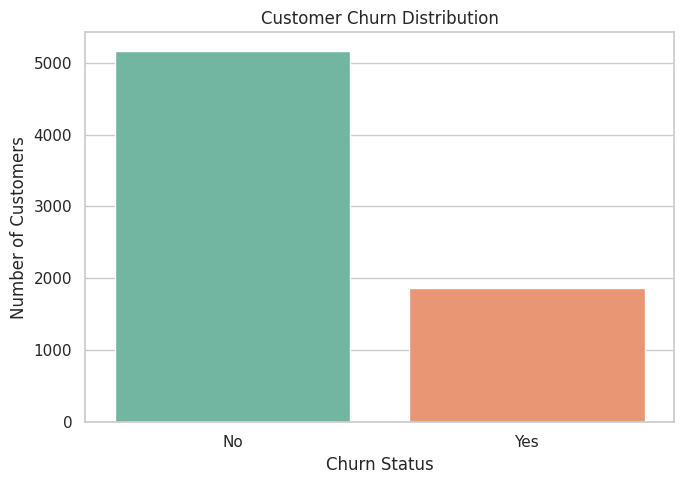

Churn Percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='Churn',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print("Churn Percentage:")
print(df_clean['Churn'].value_counts(normalize=True) * 100)

##### Step 5.2: Churn Rate by Contract Type

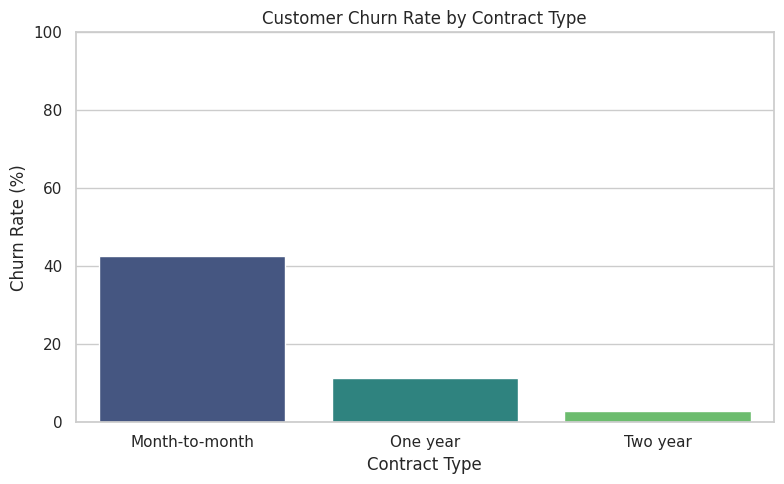

Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn_Encoded, dtype: float64


In [17]:
contract_churn = (
    df_clean.groupby('Contract')['Churn_Encoded']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values,
    hue=contract_churn.index,
    palette='viridis',
    legend=False
)

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(contract_churn.round(2))


##### Step 5.3: Customer Tenure Distribution

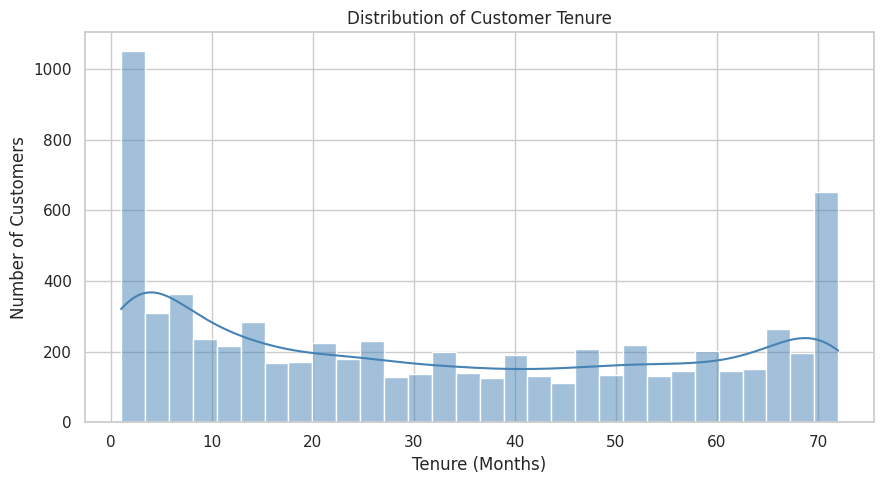

Average Tenure: 32.42


In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x='tenure',
    bins=30,
    kde=True,
    color='steelblue'
)

plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

print("Average Tenure:",
      round(df_clean['tenure'].mean(), 2))

##### Step 5.4: Monthly Charges vs Churn

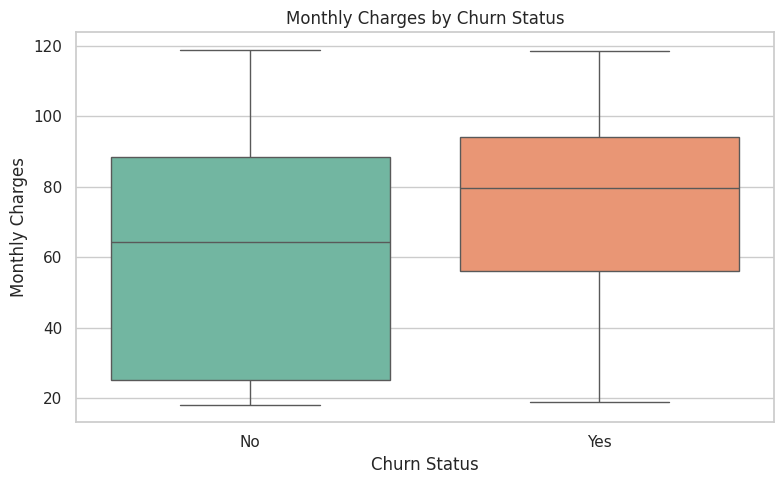

Average Monthly Charges by Churn:
Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.show()

print("Average Monthly Charges by Churn:")
print(
    df_clean.groupby('Churn')['MonthlyCharges']
    .mean()
    .round(2)
)


##### Step 5.5: Churn Rate by Payment Method

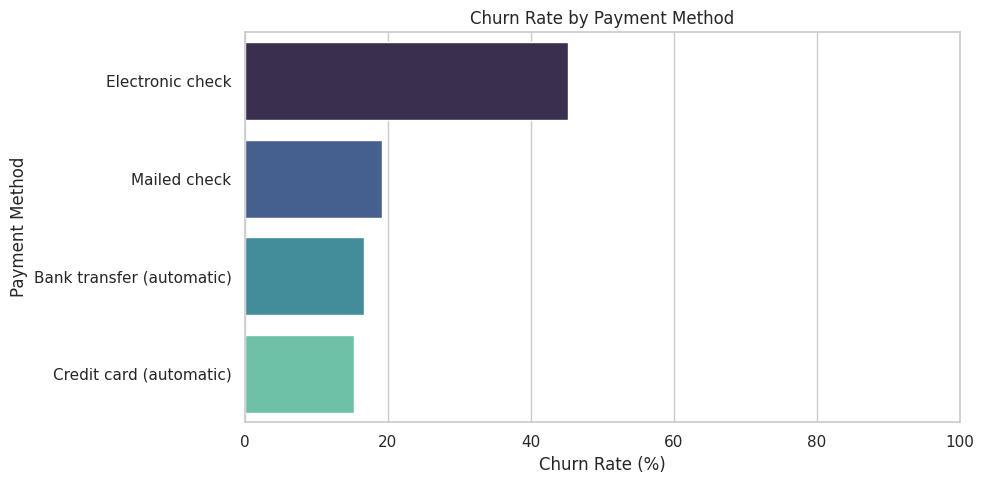

PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn_Encoded, dtype: float64


In [21]:
payment_churn = (
    df_clean.groupby('PaymentMethod')['Churn_Encoded']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.values,
    y=payment_churn.index,
    hue=payment_churn.index,
    palette='mako',
    legend=False
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Payment Method')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

print(payment_churn.round(2))

##### Step 5.6: Churn Rate by Internet Service

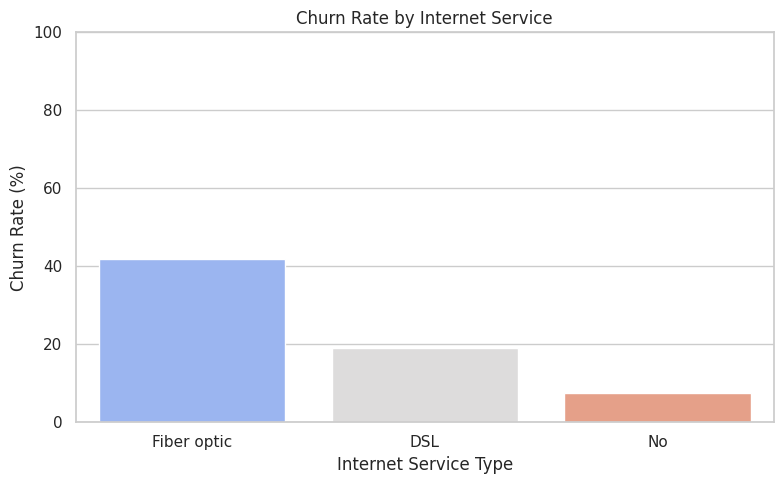

InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn_Encoded, dtype: float64


In [22]:
internet_churn = (
    df_clean.groupby('InternetService')['Churn_Encoded']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values,
    hue=internet_churn.index,
    palette='coolwarm',
    legend=False
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service Type')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(internet_churn.round(2))

##### Step 5.7: Statistical Summary of Customer Churn

In [23]:
print("Total Customers:", len(df_clean))

print("Churned Customers:",
      df_clean['Churn_Encoded'].sum())

print("Overall Churn Rate (%):",
      round(df_clean['Churn_Encoded'].mean() * 100, 2))

print("Average Monthly Charges:",
      round(df_clean['MonthlyCharges'].mean(), 2))

print("Average Customer Tenure:",
      round(df_clean['tenure'].mean(), 2))

print("Average Total Charges:",
      round(df_clean['TotalCharges'].mean(), 2))


Total Customers: 7032
Churned Customers: 1869
Overall Churn Rate (%): 26.58
Average Monthly Charges: 64.8
Average Customer Tenure: 32.42
Average Total Charges: 2283.3


### Step 6: Machine Learning Model Development and Evaluation

**Objective:** To develop supervised machine learning models for predicting customer churn using Scikit-learn.

Two classification algorithms, Logistic Regression and Random Forest, are implemented and compared. The models are evaluated using accuracy, precision, recall, F1-score, and confusion matrices to assess their ability to identify customers likely to leave the company.

##### Step 6.1: Prepare Features and Target

In [24]:
X = df_clean.drop(
    columns=['customerID', 'Churn', 'Churn_Encoded']
)

y = df_clean['Churn_Encoded'].astype(int)

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Feature Dataset Shape: (7032, 19)
Target Dataset Shape: (7032,)

Target Distribution:
Churn_Encoded
0    5163
1    1869
Name: count, dtype: int64


##### Step 6.2: Train-Test Split

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 5625
Testing Records: 1407


##### Step 6.3: Create Preprocessing Pipeline


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.pipeline import Pipeline

numerical_features = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(
            handle_unknown='ignore'
        ), categorical_features)
    ]
)

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


##### Step 6.4: Logistic Regression Model

In [27]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


##### Step 6.5: Random Forest Model

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")

Random Forest trained successfully!


##### Step 6.6: Model Evaluation


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

results = [
    evaluate_model(
        'Logistic Regression',
        y_test,
        lr_predictions
    ),
    evaluate_model(
        'Random Forest',
        y_test,
        rf_predictions
    )
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

print("\nLogistic Regression Report:")
print(classification_report(y_test, lr_predictions))

print("\nRandom Forest Report:")
print(classification_report(y_test, rf_predictions))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080
1,Random Forest,0.7875,0.6307,0.4840,0.5477



Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Random Forest Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



##### Step 6.7: Confusion Matrix Visualization


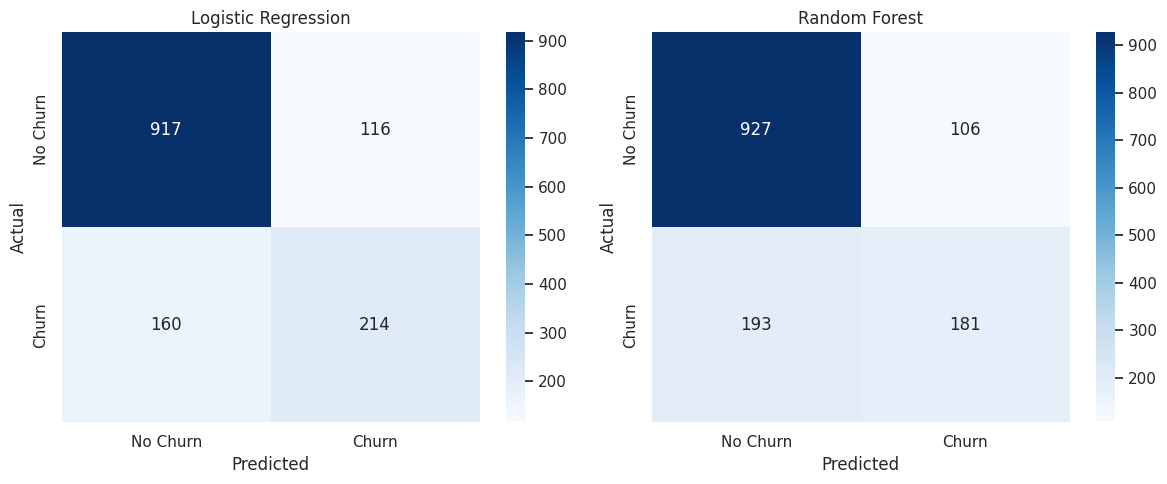

In [30]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ('Logistic Regression', lr_predictions),
    ('Random Forest', rf_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


##### Step 6.8: Model Performance Comparison


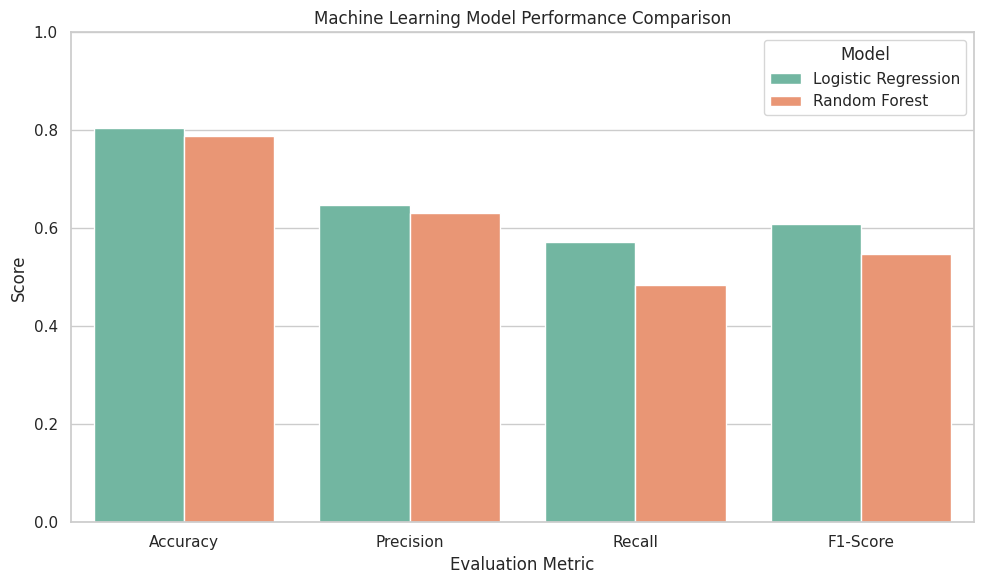

In [33]:
comparison_df = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x='Metric',
    y='Score',
    hue='Model',
    palette='Set2'
)

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Evaluation Metric')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

##### Step 6.9: Identify Best Model

In [34]:
best_model_row = results_df.loc[
    results_df['F1-Score'].idxmax()
]

best_model_name = best_model_row['Model']

best_model = (
    lr_model
    if best_model_name == 'Logistic Regression'
    else rf_model
)

print("Best Performing Model:", best_model_name)
print("Accuracy:", round(best_model_row['Accuracy'], 4))
print("Precision:", round(best_model_row['Precision'], 4))
print("Recall:", round(best_model_row['Recall'], 4))
print("F1-Score:", round(best_model_row['F1-Score'], 4))


Best Performing Model: Logistic Regression
Accuracy: 0.8038
Precision: 0.6485
Recall: 0.5722
F1-Score: 0.608


### Step 7: Conclusion and Learning Outcomes

#### Conclusion

The Data Science Tool Mastery Project demonstrates the practical application of Python and industry-standard data science libraries to customer churn analysis and prediction.

The project involved dataset exploration, data cleaning, statistical analysis, exploratory data analysis, feature preprocessing, machine learning model development, and performance evaluation.

Pandas and NumPy were used for data manipulation and numerical analysis, while Matplotlib and Seaborn supported the visualization of customer behavior and churn patterns. Scikit-learn was used to implement Logistic Regression and Random Forest classification models.

The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices. These evaluation techniques provide insights into how effectively the models identify customers at risk of churn.

#### Learning Outcomes

- Gained practical experience with Python-based data science tools.
- Applied Pandas and NumPy for data manipulation and statistical analysis.
- Performed data cleaning and preprocessing on a real-world dataset.
- Created informative visualizations using Matplotlib and Seaborn.
- Developed classification models using Scikit-learn.
- Evaluated machine learning models using standard classification metrics.
- Improved understanding of end-to-end data science workflows.

#### Future Scope

The project can be extended through hyperparameter tuning, cross-validation, feature importance analysis, additional classification algorithms, and deployment of a churn prediction application.